# Jupyter-Notebook: Ein Einstieg

Jupyter ist eine interaktive Arbeitsumgebung: Du kannst Text, Python-Code und Ergebnisse in einem Dokument kombinieren. Das ist besonders praktisch, um Daten zu erkunden, Berechnungen Schritt für Schritt auszuprobieren, Diagramme zu erstellen und Analysen nachvollziehbar zu dokumentieren.

## 1. Jupyter Notebook installieren und starten

Falls Jupyter noch nicht installiert ist, führe im Terminal aus:

```bash
pip install notebook
jupyter notebook
```

Der Startbefehl öffnet Jupyter im Browser. Dort kannst du einen Ordner öffnen und über **New > Python 3** ein Notebook anlegen. In VS Code lässt sich eine `.ipynb`-Datei ebenfalls direkt öffnen; dafür wird die Jupyter-Erweiterung benötigt.

## 2. Eine Zelle erstellen und ausführen

Ein Notebook besteht aus Zellen. In einer **Code-Zelle** steht Python, in einer **Markdown-Zelle** stehen formatierte Erklärungen wie diese. Wähle **+ Code**, tippe Python ein und drücke **Shift+Enter**, um die Zelle auszuführen und zur nächsten zu gehen. Das Ergebnis erscheint direkt darunter.

Zellen teilen sich einen laufenden Python-Kernel. Führe sie daher in der passenden Reihenfolge aus: Eine Variable muss zuerst angelegt werden, bevor eine spätere Zelle sie verwenden kann. Mit **Kernel > Restart** kannst du den Zustand zurücksetzen.

## 3. Einfaches Python-Beispiel: Rechnen mit Zahlen

In der nächsten Zelle speichern wir zwei Zahlen in Variablen, addieren sie und geben das Ergebnis aus. Erwartete Ausgabe: `7 + 5 = 12`.

In [1]:
zahl_a = 7
zahl_b = 5
summe = zahl_a + zahl_b

print(f"{zahl_a} + {zahl_b} = {summe}")

7 + 5 = 12


## 4. Visualisierung: Eine einfache Grafik mit Matplotlib

Mit Matplotlib kannst du Werte sichtbar machen. Die folgende Code-Zelle zeichnet die Temperaturen einer Beispielwoche als Liniendiagramm. Falls Matplotlib noch fehlt, installiere es im Terminal mit `pip install matplotlib`. Erwartet wird ein Diagramm mit einem Punkt pro Wochentag.

In [3]:
# Bei Bedarf einmal ausführen, wenn matplotlib noch nicht installiert ist:
%pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 63.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 62.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 46.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 53.8 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 64.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [matplotlib]8 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


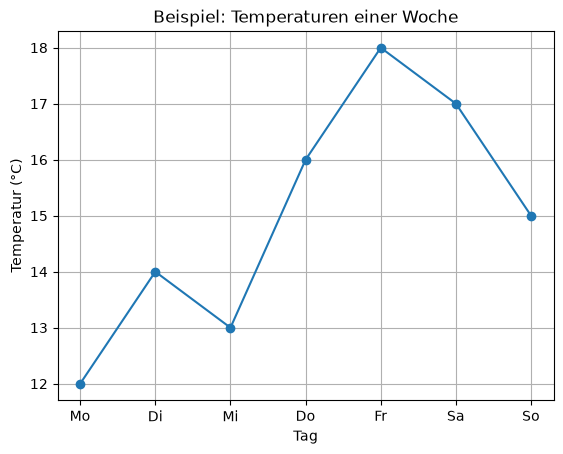

In [5]:
import matplotlib.pyplot as plt

tage = ["Mo", "Di", "Mi", "Do", "Fr", "Sa", "So"]
temperaturen = [12, 14, 13, 16, 18, 17, 15]

plt.plot(tage, temperaturen, marker="o")
plt.title("Beispiel: Temperaturen einer Woche")
plt.xlabel("Tag")
plt.ylabel("Temperatur (°C)")
plt.grid(True)
plt.show()

## Ergänzendes Beispiel: WLTP-Kraftstoffverbrauch des VW Golf

Die offizielle VW-Modellseite nennt folgende kombinierte WLTP-Spannen für den Golf: Diesel **4,3-5,0 l/100 km**, Benzin **4,5-7,3 l/100 km**. Die Bereiche fassen verschiedene Motorisierungen und Ausstattungen des Modellprogramms zusammen; sie sind keine Messwerte eines einzelnen Fahrzeugs. Quelle: [Volkswagen Golf](https://www.volkswagen.de/de/modelle/golf.html) (abgerufen am 02.11.2026).

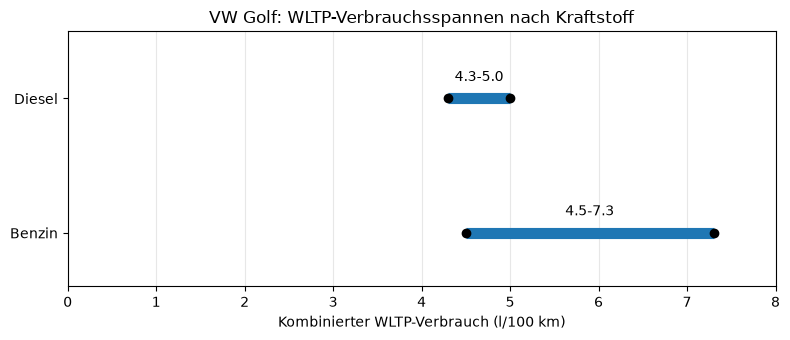

In [6]:
kraftstoff = ["Diesel", "Benzin"]
verbrauch_min = [4.3, 4.5]
verbrauch_max = [5.0, 7.3]
positionen = [1, 0]

fig, ax = plt.subplots(figsize=(8, 3.5))
for name, minimum, maximum, y in zip(kraftstoff, verbrauch_min, verbrauch_max, positionen):
    ax.hlines(y, minimum, maximum, linewidth=8)
    ax.scatter([minimum, maximum], [y, y], color="black", zorder=3)
    ax.text((minimum + maximum) / 2, y + 0.13, f"{minimum:.1f}-{maximum:.1f}", ha="center")

ax.set_yticks(positionen, kraftstoff)
ax.set_xlabel("Kombinierter WLTP-Verbrauch (l/100 km)")
ax.set_title("VW Golf: WLTP-Verbrauchsspannen nach Kraftstoff")
ax.set_xlim(0, 8)
ax.set_ylim(-0.4, 1.5)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

## WLTC: Geschwindigkeit über die Zeit (Class 3b)

Das folgende Diagramm zeigt den standardisierten WLTC-Class-3b-Geschwindigkeitsverlauf mit einem Messpunkt pro Sekunde (0 bis 1.800 s). Die vier Hintergrundbereiche markieren Low, Medium, High und Extra-High. Die Daten stammen aus der Referenzimplementierung des EU Joint Research Centre (JRC); für die Ausführung wird eine Internetverbindung benötigt. Quelle: [JRC-WLTP, V_class3b.txt](https://github.com/JRCSTU/wltp/blob/18650f372044371ed994a161a93473a75e76d2a9/wltp/cycles/V_class3b.txt).

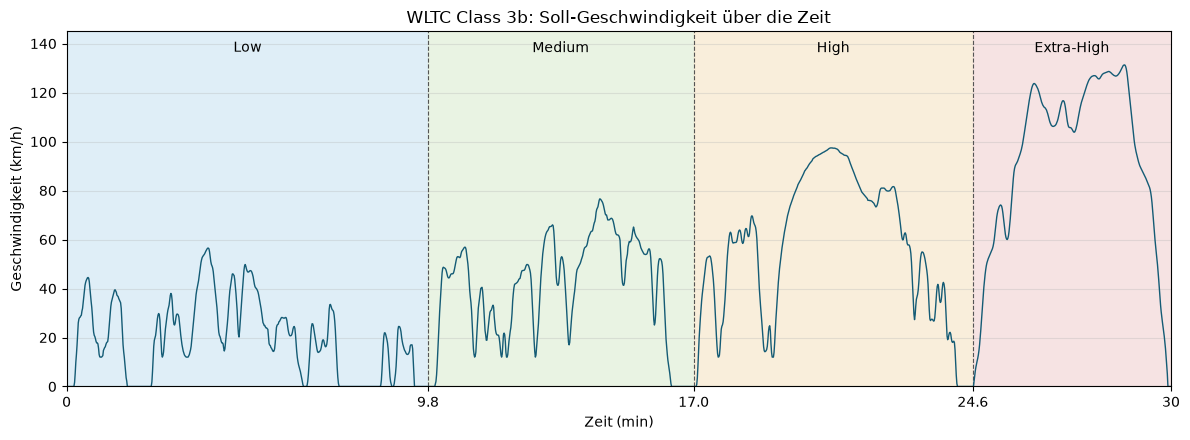

In [7]:
from urllib.request import urlopen

wltc_url = "https://raw.githubusercontent.com/JRCSTU/wltp/18650f372044371ed994a161a93473a75e76d2a9/wltp/cycles/V_class3b.txt"
with urlopen(wltc_url, timeout=30) as antwort:
    geschwindigkeit_kmh = [float(wert) for wert in antwort.read().decode("utf-8").split()]

if len(geschwindigkeit_kmh) != 1801:
    raise ValueError(f"Erwartet wurden 1801 Werte, erhalten: {len(geschwindigkeit_kmh)}")

zeit_minuten = [sekunde / 60 for sekunde in range(len(geschwindigkeit_kmh))]
phasen = [
    ("Low", 0, 589, "#d8eaf5"),
    ("Medium", 589, 1022, "#e4f0dc"),
    ("High", 1022, 1477, "#f8ead2"),
    ("Extra-High", 1477, 1800, "#f4dddd"),
]

fig, ax = plt.subplots(figsize=(12, 4.5))
for name, start, ende, farbe in phasen:
    ax.axvspan(start / 60, ende / 60, color=farbe, alpha=0.8)
    ax.text((start + ende) / 120, 141, name, ha="center", va="top")

for grenze in (589, 1022, 1477):
    ax.axvline(grenze / 60, color="#555555", linestyle="--", linewidth=0.8)

ax.plot(zeit_minuten, geschwindigkeit_kmh, color="#145b75", linewidth=1)
ax.set_xlim(0, 30)
ax.set_ylim(0, 145)
ax.set_xticks([0, 589 / 60, 1022 / 60, 1477 / 60, 30], ["0", "9.8", "17.0", "24.6", "30"])
ax.set_xlabel("Zeit (min)")
ax.set_ylabel("Geschwindigkeit (km/h)")
ax.set_title("WLTC Class 3b: Soll-Geschwindigkeit über die Zeit")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

## 5. Notebook speichern und exportieren

Speichere deine Arbeit regelmäßig mit **Strg+S** (macOS: **Cmd+S**). Das Notebook bleibt als `.ipynb` erhalten und enthält Zellen, Code und Ergebnisse. In Jupyter Notebook findest du PDF- und andere Exportmöglichkeiten unter **File > Save and Export Notebook As**. Für den PDF-Export kann eine zusätzliche LaTeX-Installation erforderlich sein; alternativ lässt sich das Notebook als HTML exportieren und anschließend aus dem Browser drucken.

**Ausprobieren:** Ändere einen Temperaturwert in der Diagramm-Zelle und führe sie erneut mit **Shift+Enter** aus. So siehst du, wie sich die Darstellung verändert.